# 3. Exploratory Data Analysis

The purpose of this notebook is to identify sales patterns, product performance, geographical trends, and customer behavior in the Online Retail dataset.

We will use Python, Pandas, NumPy, Matplotlib, and Seaborn to calculate business metrics and create visualizations that support data-driven decisions.

In [1]:
# ==============================================================================
# IMPORT LIBRARIES AND LOAD CLEANED DATASET
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

project_root = Path.cwd().parent
clean_file = project_root / "data" / "processed" / "online_retail_clean.csv"

retail = pd.read_csv(
    clean_file,
    parse_dates=["InvoiceDate"]
)

print("RetailPulse - Exploratory Data Analysis")
print(f"Dataset shape: {retail.shape}")
print(f"Date range: {retail['InvoiceDate'].min()} to {retail['InvoiceDate'].max()}")

RetailPulse - Exploratory Data Analysis
Dataset shape: (536641, 17)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


In [2]:
# ==============================================================================
# CALCULATE BASELINE SALES, RETURNS, AND DATASET METRICS
# ==============================================================================
positive_sales = retail.loc[retail["IsPositiveSale"]].copy()
returns = retail.loc[retail["Quantity"] < 0].copy()

total_records = len(retail)
total_sales_lines = len(positive_sales)
total_return_lines = len(returns)

gross_sales_revenue = positive_sales["Revenue"].sum()
return_value = returns["Revenue"].abs().sum()
net_revenue = gross_sales_revenue - return_value

unique_customers = retail["CustomerID"].nunique()
unique_products = retail["StockCode"].nunique()
unique_countries = retail["Country"].nunique()

overview = pd.Series({
    "Total transaction rows": total_records,
    "Positive sales lines": total_sales_lines,
    "Negative-quantity lines": total_return_lines,
    "Gross sales revenue": gross_sales_revenue,
    "Return/adjustment value (absolute)": return_value,
    "Net revenue (sales less negative lines)": net_revenue,
    "Unique identified customers": unique_customers,
    "Unique products": unique_products,
    "Unique countries": unique_countries
})

overview

Total transaction rows                     5.366410e+05
Positive sales lines                       5.248780e+05
Negative-quantity lines                    1.058700e+04
Gross sales revenue                        1.064211e+07
Return/adjustment value (absolute)         8.939797e+05
Net revenue (sales less negative lines)    9.748131e+06
Unique identified customers                4.372000e+03
Unique products                            4.070000e+03
Unique countries                           3.800000e+01
dtype: float64

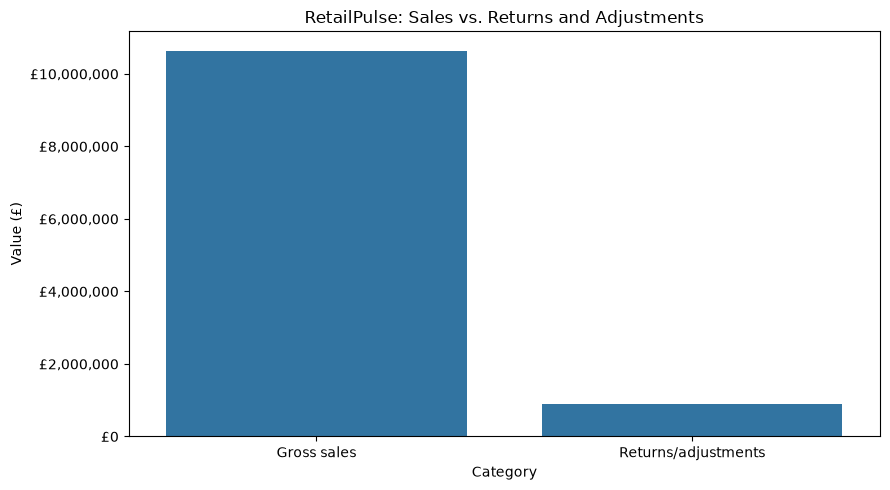

In [3]:
# ==============================================================================
# PLOT GROSS SALES REVENUE VS. VALUE OF NEGATIVE-QUANTITY LINES
# ==============================================================================
revenue_comparison = pd.Series({
    "Gross sales": gross_sales_revenue,
    "Returns/adjustments": return_value
})

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=revenue_comparison.index,
    y=revenue_comparison.values
)

ax.set_title("RetailPulse: Sales vs. Returns and Adjustments")
ax.set_xlabel("Category")
ax.set_ylabel("Value (£)")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, position: f"£{value:,.0f}")
)

plt.tight_layout()
plt.show()

In [4]:
# ==============================================================================
# EXPORT INITIAL BUSINESS OVERVIEW TO REPORTS FOLDER
# ==============================================================================
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

overview.to_csv(reports_dir / "business_overview.csv", header=["Value"])

print(f"Business overview saved to: {reports_dir / 'business_overview.csv'}")

Business overview saved to: c:\Users\saura\OneDrive\Documents\Data Science Projects\RetailPulse\reports\business_overview.csv


# 4. Monthly Sales Trend Analysis

This section examines monthly sales performance to identify revenue patterns and potential seasonality.

We aggregate positive sales revenue by month and analyze negative-quantity transactions separately to avoid confusing gross sales with returns and other adjustments.

In [5]:
# Aggregate sales revenue and negative-quantity adjustments by month
retail["YearMonth"] = retail["InvoiceDate"].dt.to_period("M").astype(str)

monthly_sales = (
    retail.loc[retail["IsPositiveSale"]]
    .groupby("YearMonth", as_index=False)
    .agg(
        GrossSales=("Revenue", "sum"),
        Transactions=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
)

monthly_adjustments = (
    retail.loc[retail["Quantity"] < 0]
    .groupby("YearMonth", as_index=False)
    .agg(
        AdjustmentValue=("Revenue", lambda values: values.abs().sum())
    )
)

monthly_sales = monthly_sales.merge(
    monthly_adjustments,
    on="YearMonth",
    how="left"
)

monthly_sales["AdjustmentValue"] = monthly_sales["AdjustmentValue"].fillna(0)

monthly_sales.head(12)

,YearMonth,GrossSales,Transactions,UnitsSold,AdjustmentValue
0,2010-12,821452.730,1559,358019,74729.12
1,2011-01,689811.610,1086,387099,131363.05
2,2011-02,522545.560,1100,282934,25519.15
3,2011-03,716215.260,1454,376599,34201.28
4,2011-04,536968.491,1246,307953,44600.65
5,2011-05,769296.610,1681,395001,47202.51
6,2011-06,760547.010,1533,388511,70569.78
7,2011-07,718076.121,1475,399693,37919.13
8,2011-08,757841.380,1361,421020,54330.80
9,2011-09,1056435.192,1837,569573,38838.51


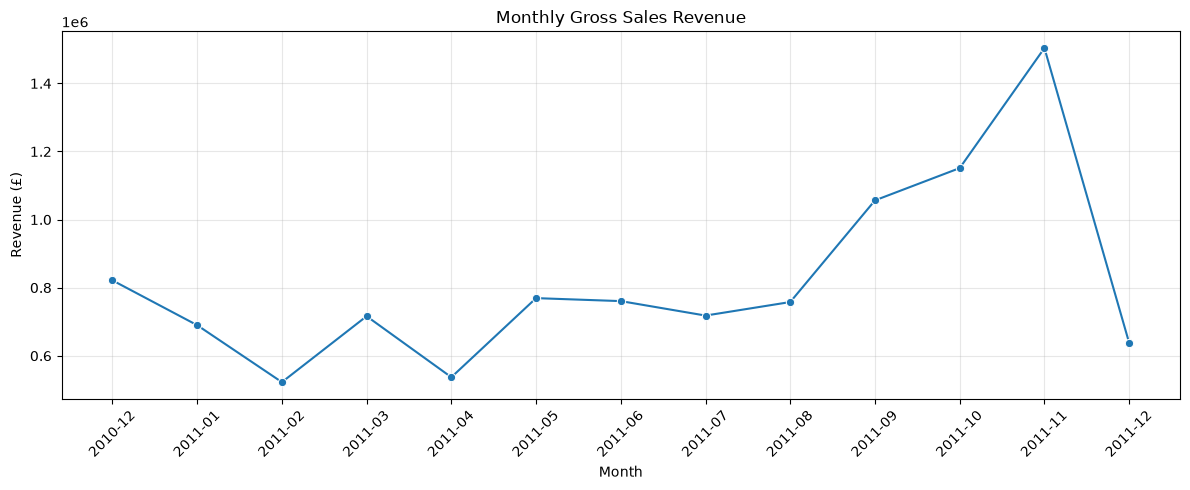

In [6]:
# Visualize monthly gross sales revenue
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="YearMonth",
    y="GrossSales",
    marker="o"
)

plt.title("Monthly Gross Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

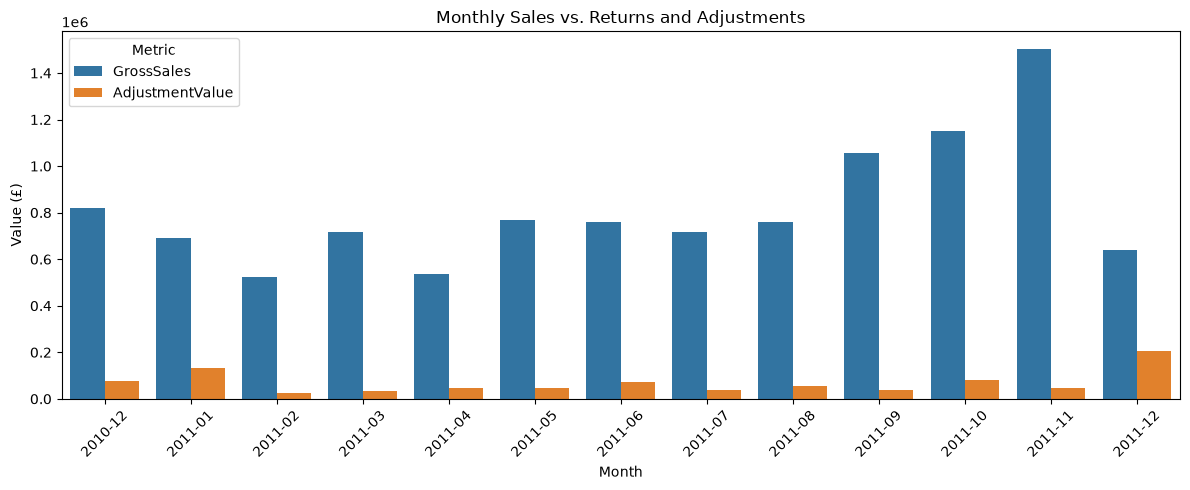

In [7]:
# Plot monthly sales and negative-quantity adjustment values together
monthly_comparison = monthly_sales.melt(
    id_vars="YearMonth",
    value_vars=["GrossSales", "AdjustmentValue"],
    var_name="Metric",
    value_name="Amount"
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=monthly_comparison,
    x="YearMonth",
    y="Amount",
    hue="Metric"
)

plt.title("Monthly Sales vs. Returns and Adjustments")
plt.xlabel("Month")
plt.ylabel("Value (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
# Find the months with the highest and lowest gross sales revenue
best_month = monthly_sales.loc[monthly_sales["GrossSales"].idxmax()]
worst_month = monthly_sales.loc[monthly_sales["GrossSales"].idxmin()]

print("Highest gross sales month:")
print(best_month)

print("\nLowest gross sales month:")
print(worst_month)

Highest gross sales month:
YearMonth             2011-11
GrossSales         1503866.78
Transactions             2769
UnitsSold              751377
AdjustmentValue      47720.98
Name: 11, dtype: object

Lowest gross sales month:
YearMonth            2011-02
GrossSales         522545.56
Transactions            1100
UnitsSold             282934
AdjustmentValue     25519.15
Name: 2, dtype: object


In [9]:
# Calculate month-over-month gross sales growth as a percentage
monthly_sales["PreviousMonthSales"] = monthly_sales["GrossSales"].shift(1)

monthly_sales["MoMGrowthPercent"] = (
    (monthly_sales["GrossSales"] - monthly_sales["PreviousMonthSales"])
    / monthly_sales["PreviousMonthSales"]
    * 100
)

monthly_sales[[
    "YearMonth",
    "GrossSales",
    "PreviousMonthSales",
    "MoMGrowthPercent"
]]

,YearMonth,GrossSales,PreviousMonthSales,MoMGrowthPercent
0,2010-12,821452.730,NaN,NaN
1,2011-01,689811.610,821452.730,-16.025404
2,2011-02,522545.560,689811.610,-24.248077
3,2011-03,716215.260,522545.560,37.062740
4,2011-04,536968.491,716215.260,-25.026941
5,2011-05,769296.610,536968.491,43.266620
6,2011-06,760547.010,769296.610,-1.137351
7,2011-07,718076.121,760547.010,-5.584256
8,2011-08,757841.380,718076.121,5.537750
9,2011-09,1056435.192,757841.380,39.400568


# 5. Product Performance Analysis

This section evaluates product performance using sales quantity, gross sales revenue, and invoice counts. We also investigate products appearing in negative-quantity transactions to identify potential return or adjustment patterns.

The analysis uses the cleaned dataset and excludes non-positive-price or non-positive-quantity rows from standard sales metrics.

In [10]:
# Aggregate sales quantity, revenue, and invoice counts by product
product_sales = (
    retail.loc[retail["IsPositiveSale"]]
    .groupby("StockCode", as_index=False)
    .agg(
        ProductDescription=("Description", "first"),
        UnitsSold=("Quantity", "sum"),
        GrossRevenue=("Revenue", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        AverageUnitPrice=("UnitPrice", "mean")
    )
    .sort_values("GrossRevenue", ascending=False)
)

product_sales.head(10)

,StockCode,ProductDescription,UnitsSold,GrossRevenue,InvoiceCount,AverageUnitPrice
3911,DOT,DOTCOM POSTAGE,706,206248.77,706,292.137068
1310,22423,REGENCY CAKESTAND 3 TIER,13851,174156.54,1988,13.983936
2465,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1,2.080000
3407,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37641,104462.75,2198,3.117838
2670,47566,PARTY BUNTING,18283,99445.23,1685,5.797928
3387,85099B,JUMBO BAG RED RETROSPOT,48371,94159.81,2089,2.486197
2020,23166,MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247,1.468480
3914,POST,POSTAGE,3150,78101.88,1126,31.076581
3912,M,Manual,6984,77750.27,289,234.489652
1942,23084,RABBIT NIGHT LIGHT,30739,66870.03,994,2.386401


     StockCode                  ProductDescription  UnitsSold  GrossRevenue  \
3911       DOT                      DOTCOM POSTAGE        706     206248.77   
1310     22423            REGENCY CAKESTAND 3 TIER      13851     174156.54   
2465     23843         PAPER CRAFT , LITTLE BIRDIE      80995     168469.60   
3407    85123A  WHITE HANGING HEART T-LIGHT HOLDER      37641     104462.75   
2670     47566                       PARTY BUNTING      18283      99445.23   
3387    85099B             JUMBO BAG RED RETROSPOT      48371      94159.81   
2020     23166      MEDIUM CERAMIC TOP STORAGE JAR      78033      81700.92   
3914      POST                             POSTAGE       3150      78101.88   
3912         M                              Manual       6984      77750.27   
1942     23084                  RABBIT NIGHT LIGHT      30739      66870.03   

      InvoiceCount  
3911           706  
1310          1988  
2465             1  
3407          2198  
2670          1685  
3387

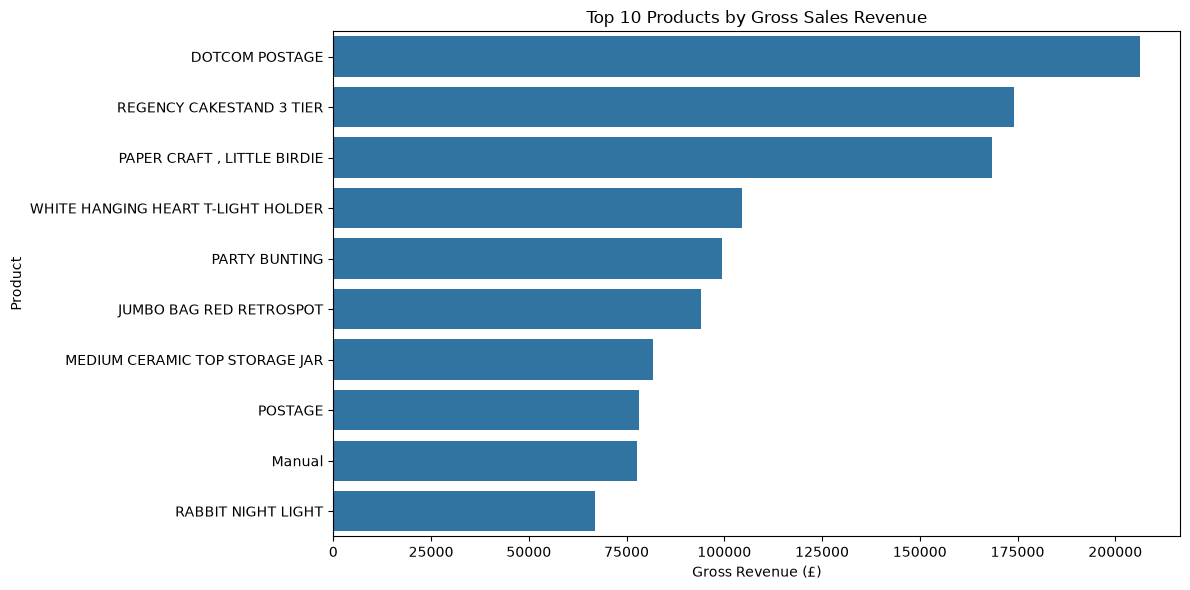

In [11]:
# Display the ten products generating the highest gross sales revenue
top_products_revenue = product_sales.head(10).copy()

print(top_products_revenue[[
    "StockCode",
    "ProductDescription",
    "UnitsSold",
    "GrossRevenue",
    "InvoiceCount"
]])

# Plot the top ten products by gross sales revenue
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products_revenue,
    x="GrossRevenue",
    y="ProductDescription"
)

plt.title("Top 10 Products by Gross Sales Revenue")
plt.xlabel("Gross Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

     StockCode                  ProductDescription  UnitsSold  GrossRevenue  \
2465     23843         PAPER CRAFT , LITTLE BIRDIE      80995     168469.60   
2020     23166      MEDIUM CERAMIC TOP STORAGE JAR      78033      81700.92   
1109     22197                SMALL POPCORN HOLDER      56898      51334.47   
2909     84077   WORLD WAR 2 GLIDERS ASSTD DESIGNS      54951      13814.01   
3387    85099B             JUMBO BAG RED RETROSPOT      48371      94159.81   
3407    85123A  WHITE HANGING HEART T-LIGHT HOLDER      37641     104462.75   
439      21212     PACK OF 72 RETROSPOT CAKE CASES      36396      21246.45   
3194     84879       ASSORTED COLOUR BIRD ORNAMENT      36362      58927.62   
1942     23084                  RABBIT NIGHT LIGHT      30739      66870.03   
1374     22492              MINI PAINT SET VINTAGE      26633      16937.82   

      InvoiceCount  
2465             1  
2020           247  
1109          1392  
2909           535  
3387          2089  
3407

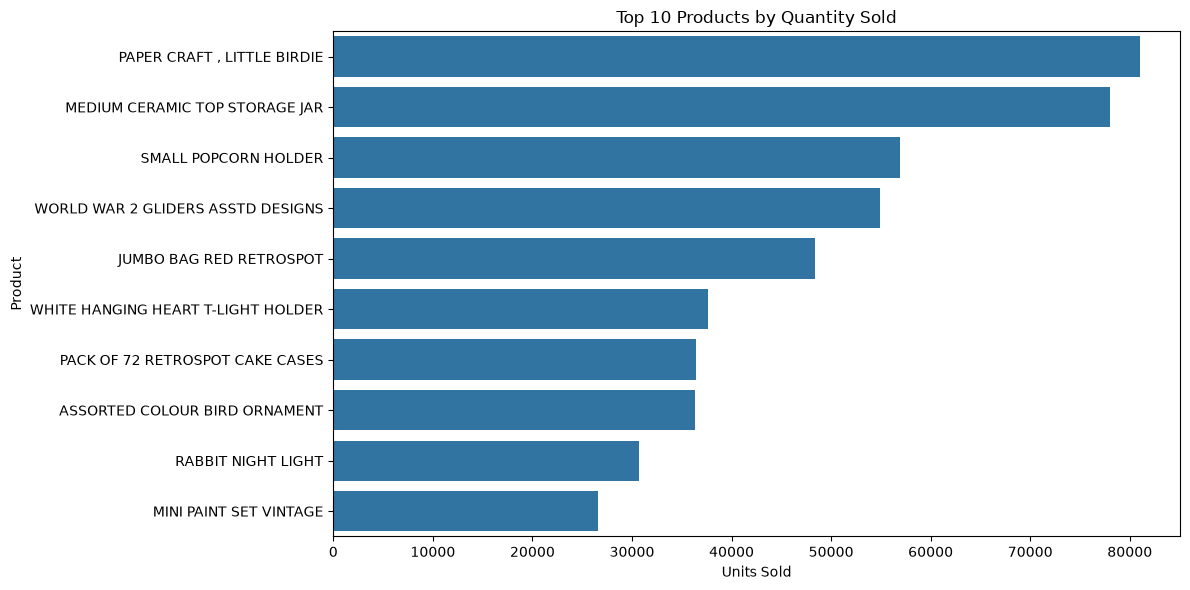

In [12]:
# Identify the ten products with the highest total sales quantity
top_products_quantity = (
    product_sales
    .sort_values("UnitsSold", ascending=False)
    .head(10)
    .copy()
)

print(top_products_quantity[[
    "StockCode",
    "ProductDescription",
    "UnitsSold",
    "GrossRevenue",
    "InvoiceCount"
]])

# Visualize the ten products with the highest unit sales
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_products_quantity,
    x="UnitsSold",
    y="ProductDescription"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [13]:
# Rank products by the number of distinct invoices containing them
top_products_by_invoices = (
    product_sales
    .sort_values("InvoiceCount", ascending=False)
    .head(10)
    .copy()
)

top_products_by_invoices[[
    "StockCode",
    "ProductDescription",
    "InvoiceCount",
    "UnitsSold",
    "GrossRevenue"
]]

,StockCode,ProductDescription,InvoiceCount,UnitsSold,GrossRevenue
3407,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2198,37641,104462.75
3387,85099B,JUMBO BAG RED RETROSPOT,2089,48371,94159.81
1310,22423,REGENCY CAKESTAND 3 TIER,1988,13851,174156.54
2670,47566,PARTY BUNTING,1685,18283,99445.23
175,20725,LUNCH BAG RED RETROSPOT,1565,19432,35862.36
3194,84879,ASSORTED COLOUR BIRD ORNAMENT,1455,36362,58927.62
1109,22197,SMALL POPCORN HOLDER,1392,56898,51334.47
1593,22720,SET OF 3 CAKE TINS PANTRY DESIGN,1385,7483,38108.89
439,21212,PACK OF 72 RETROSPOT CAKE CASES,1320,36396,21246.45
1276,22383,LUNCH BAG SUKI DESIGN,1284,12518,22486.34


     StockCode                   ProductDescription  NegativeQuantity  \
1769     23843          PAPER CRAFT , LITTLE BIRDIE            -80995   
1515     23166       MEDIUM CERAMIC TOP STORAGE JAR            -74494   
1398     23005     TRAVEL CARD WALLET I LOVE LONDON            -19201   
2073     84347  ROTATING SILVER ANGELS T-LIGHT HLDR             -9376   
1396     23003         Printing smudges/thrown away             -9058   
1947    72140F                           throw away             -5368   
2010    79323W                  WHITE CHERRY LIGHTS             -4838   
26       16045                                check             -4567   
94       20713                       JUMBO BAG OWLS             -4165   
2556         M                               Manual             -4066   

      AdjustmentLineCount  AdjustmentValue  UnitsAdjusted  
1769                    1        168469.60          80995  
1515                   10         77479.64          74494  
1398            

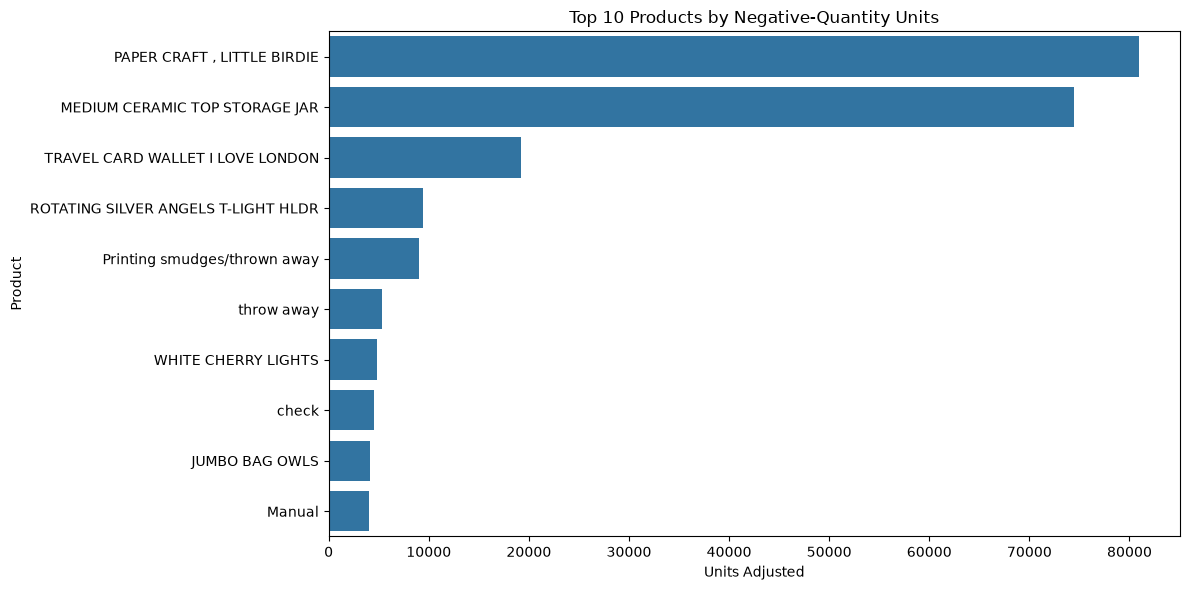

In [14]:
# Summarize negative quantities and their absolute values by product
product_adjustments = (
    retail.loc[retail["Quantity"] < 0]
    .groupby("StockCode", as_index=False)
    .agg(
        ProductDescription=("Description", "first"),
        NegativeQuantity=("Quantity", "sum"),
        AdjustmentLineCount=("InvoiceNo", "size"),
        AdjustmentValue=("Revenue", lambda values: values.abs().sum())
    )
)

product_adjustments["UnitsAdjusted"] = (
    product_adjustments["NegativeQuantity"].abs()
)

product_adjustments = product_adjustments.sort_values(
    "UnitsAdjusted",
    ascending=False
)

top_adjusted_products = product_adjustments.head(10)

print(top_adjusted_products)

# Plot the ten products with the largest negative-quantity totals
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_adjusted_products,
    x="UnitsAdjusted",
    y="ProductDescription"
)

plt.title("Top 10 Products by Negative-Quantity Units")
plt.xlabel("Units Adjusted")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [15]:
# Export product sales and adjustment summaries to the reports folder
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

product_sales.to_csv(
    reports_dir / "product_sales_summary.csv",
    index=False
)

product_adjustments.to_csv(
    reports_dir / "product_adjustments_summary.csv",
    index=False
)

print("Product sales summary saved.")
print("Product adjustments summary saved.")

Product sales summary saved.
Product adjustments summary saved.


# 6. Country and Geographical Sales Analysis

This section compares retail performance across countries using gross sales revenue, units sold, distinct invoices, and identified customers.

Standard sales metrics include only rows classified as positive sales. Returns and other negative-quantity adjustments are analyzed separately to keep the measures consistent.

In [16]:
# Aggregate sales revenue, quantity, invoices, and customers by country
country_sales = (
    retail.loc[retail["IsPositiveSale"]]
    .groupby("Country", as_index=False)
    .agg(
        GrossRevenue=("Revenue", "sum"),
        UnitsSold=("Quantity", "sum"),
        InvoiceCount=("InvoiceNo", "nunique"),
        IdentifiedCustomers=("CustomerID", "nunique"),
        ProductTypes=("StockCode", "nunique")
    )
    .sort_values("GrossRevenue", ascending=False)
)

country_sales.head(15)

,Country,GrossRevenue,UnitsSold,InvoiceCount,IdentifiedCustomers,ProductTypes
36,United Kingdom,9001744.094,4646906,18019,3920,3916
24,Netherlands,285446.340,200361,94,9,782
10,EIRE,283140.520,147007,288,3,1968
14,Germany,228678.400,119154,457,94,1664
13,France,209625.370,112060,392,87,1542
0,Australia,138453.810,83891,57,9,599
31,Spain,61558.560,27933,90,30,1091
33,Switzerland,57067.600,30617,54,21,978
3,Belgium,41196.340,23237,98,25,777
32,Sweden,38367.830,36078,36,8,261


           Country  GrossRevenue  UnitsSold  InvoiceCount
36  United Kingdom   9001744.094    4646906         18019
24     Netherlands    285446.340     200361            94
10            EIRE    283140.520     147007           288
14         Germany    228678.400     119154           457
13          France    209625.370     112060           392
0        Australia    138453.810      83891            57
31           Spain     61558.560      27933            90
33     Switzerland     57067.600      30617            54
3          Belgium     41196.340      23237            98
32          Sweden     38367.830      36078            36


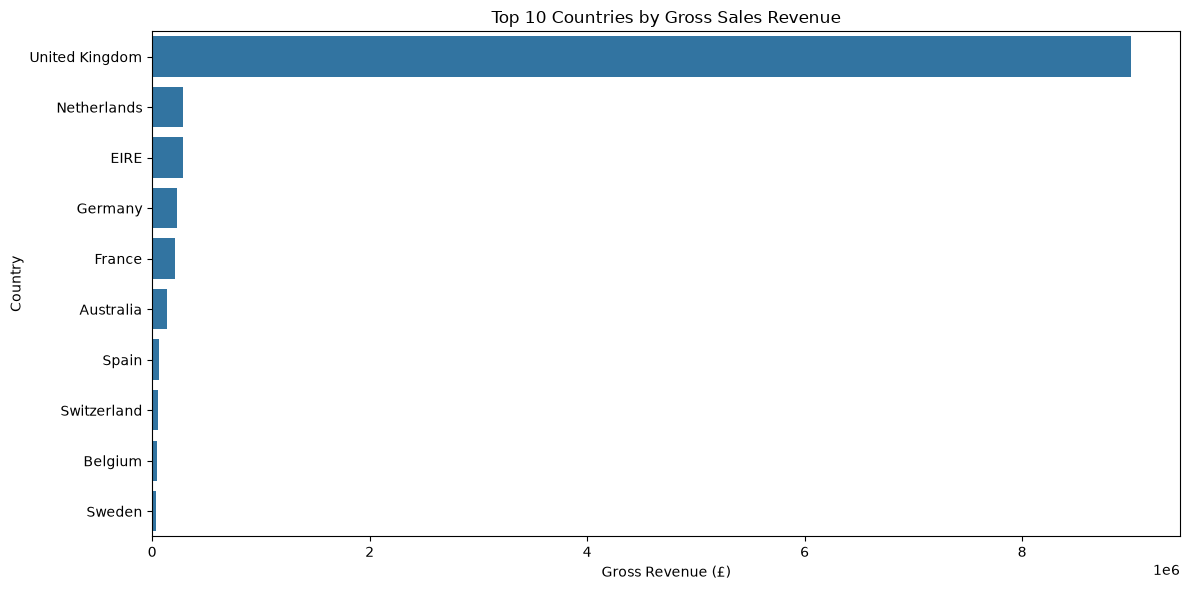

In [17]:
# Select the ten countries with the highest gross sales revenue
top_countries_revenue = country_sales.head(10).copy()

print(top_countries_revenue[
    ["Country", "GrossRevenue", "UnitsSold", "InvoiceCount"]
])

# Plot the top ten countries by gross sales revenue
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries_revenue,
    x="GrossRevenue",
    y="Country"
)

plt.title("Top 10 Countries by Gross Sales Revenue")
plt.xlabel("Gross Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

           Country  UnitsSold  GrossRevenue  InvoiceCount
36  United Kingdom    4646906   9001744.094         18019
24     Netherlands     200361    285446.340            94
10            EIRE     147007    283140.520           288
14         Germany     119154    228678.400           457
13          France     112060    209625.370           392
0        Australia      83891    138453.810            57
32          Sweden      36078     38367.830            36
33     Switzerland      30617     57067.600            54
31           Spain      27933     61558.560            90
20           Japan      26016     37416.370            19


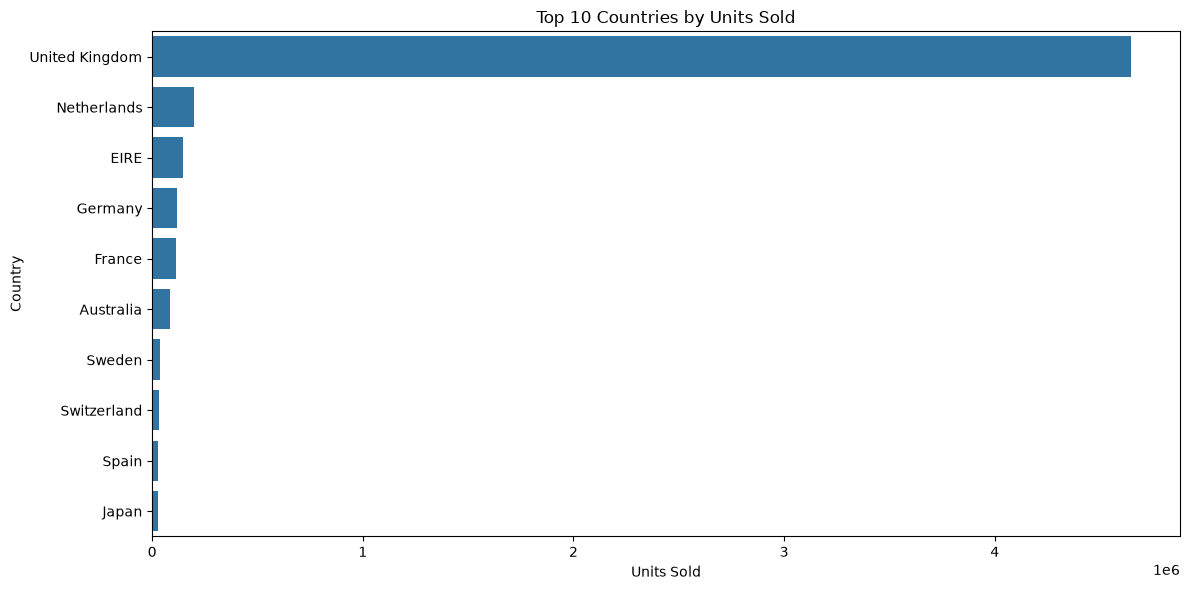

In [18]:
# Rank countries by total positive-sale quantity
top_countries_quantity = (
    country_sales
    .sort_values("UnitsSold", ascending=False)
    .head(10)
    .copy()
)

print(top_countries_quantity[
    ["Country", "UnitsSold", "GrossRevenue", "InvoiceCount"]
])

# Plot the ten countries with the highest positive-sale quantities
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_countries_quantity,
    x="UnitsSold",
    y="Country"
)

plt.title("Top 10 Countries by Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [19]:
# Calculate each country's share of total gross sales revenue
total_gross_revenue = country_sales["GrossRevenue"].sum()

country_sales["RevenueSharePercent"] = (
    country_sales["GrossRevenue"] / total_gross_revenue * 100
)

country_sales["CumulativeRevenueSharePercent"] = (
    country_sales["RevenueSharePercent"].cumsum()
)

country_sales[
    [
        "Country",
        "GrossRevenue",
        "RevenueSharePercent",
        "CumulativeRevenueSharePercent"
    ]
].head(10)

,Country,GrossRevenue,RevenueSharePercent,CumulativeRevenueSharePercent
36,United Kingdom,9001744.094,84.586078,84.586078
24,Netherlands,285446.340,2.682234,87.268312
10,EIRE,283140.520,2.660567,89.928879
14,Germany,228678.400,2.148807,92.077686
13,France,209625.370,1.969772,94.047458
0,Australia,138453.810,1.301000,95.348458
31,Spain,61558.560,0.578443,95.926901
33,Switzerland,57067.600,0.536243,96.463144
3,Belgium,41196.340,0.387107,96.850251
32,Sweden,38367.830,0.360528,97.210779


In [20]:
# Calculate gross revenue per identified customer for each country
country_sales["RevenuePerIdentifiedCustomer"] = (
    country_sales["GrossRevenue"]
    / country_sales["IdentifiedCustomers"].replace(0, np.nan)
)

country_sales.sort_values(
    "RevenuePerIdentifiedCustomer",
    ascending=False
).head(10)

,Country,GrossRevenue,UnitsSold,InvoiceCount,IdentifiedCustomers,ProductTypes,RevenueSharePercent,CumulativeRevenueSharePercent,RevenuePerIdentifiedCustomer
10,EIRE,283140.52,147007,288,3,1968,2.660567,89.928879,94380.173333
24,Netherlands,285446.34,200361,94,9,782,2.682234,87.268312,31716.260000
30,Singapore,21279.29,5241,7,1,178,0.199954,98.630519,21279.290000
0,Australia,138453.81,83891,57,9,599,1.301000,95.348458,15383.756667
32,Sweden,38367.83,36078,36,8,261,0.360528,97.210779,4795.978750
20,Japan,37416.37,26016,19,8,215,0.351588,97.562367,4677.046250
17,Iceland,4310.00,2458,7,1,103,0.040499,99.808285,4310.000000
25,Norway,36165.44,19336,36,10,591,0.339833,97.902201,3616.544000
33,Switzerland,57067.60,30617,54,21,978,0.536243,96.463144,2717.504762
18,Israel,8129.41,4406,8,3,254,0.076389,99.609583,2709.803333


In [21]:
# Summarize negative-quantity transaction values by country
country_adjustments = (
    retail.loc[retail["Quantity"] < 0]
    .groupby("Country", as_index=False)
    .agg(
        NegativeQuantity=("Quantity", "sum"),
        AdjustmentValue=("Revenue", lambda values: values.abs().sum()),
        AdjustmentLines=("InvoiceNo", "size")
    )
)

country_adjustments["UnitsAdjusted"] = (
    country_adjustments["NegativeQuantity"].abs()
)

country_adjustments = country_adjustments.sort_values(
    "AdjustmentValue",
    ascending=False
)

country_adjustments.head(10)

,Country,NegativeQuantity,AdjustmentValue,AdjustmentLines,UnitsAdjusted
29,United Kingdom,-468001,812491.79,9157,468001
8,EIRE,-4786,20147.14,301,4786
11,France,-1623,12308.26,148,1623
24,Singapore,-7,12158.90,7,7
12,Germany,-1815,7168.93,453,1815
25,Spain,-1127,6802.53,48,1127
14,Hong Kong,-4,5574.76,4,4
22,Portugal,-78,4380.08,18,78
17,Japan,-798,2075.75,37,798
28,USA,-1424,1849.47,112,1424


In [22]:
# Export country sales and adjustment summaries
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

country_sales.to_csv(
    reports_dir / "country_sales_summary.csv",
    index=False
)

country_adjustments.to_csv(
    reports_dir / "country_adjustments_summary.csv",
    index=False
)

print("Country sales summary saved.")
print("Country adjustments summary saved.")

Country sales summary saved.
Country adjustments summary saved.


# 7. Customer Behaviour Analysis

This section examines identifiable customer purchasing behaviour using invoice-level and customer-level metrics.

We analyze purchase frequency, average order value, customer revenue, and repeat purchasing patterns. Customer-level metrics exclude transactions with missing CustomerID values because they cannot be reliably assigned to individual customers.

In [23]:
# Prepare valid sales lines with identifiable customers
customer_sales_lines = retail.loc[
    retail["IsPositiveSale"] & 
    retail["CustomerID"].notna()
].copy()

# Calculate the sales value of each invoice
invoice_sales = (
    customer_sales_lines
    .groupby(["CustomerID", "InvoiceNo"], as_index=False)
    .agg(
        OrderValue=("Revenue", "sum"),
        OrderDate=("InvoiceDate", "min"),
        UnitsPurchased=("Quantity", "sum")
    )
)

invoice_sales.head()

,CustomerID,InvoiceNo,OrderValue,OrderDate,UnitsPurchased
0,12346.0,541431,77183.60,2011-01-18 10:01:00,74215
1,12347.0,537626,711.79,2010-12-07 14:57:00,319
2,12347.0,542237,475.39,2011-01-26 14:30:00,315
3,12347.0,549222,636.25,2011-04-07 10:43:00,483
4,12347.0,556201,382.52,2011-06-09 13:01:00,196


In [24]:
# Summarize customer spending, order frequency, and purchase activity
customer_summary = (
    invoice_sales
    .groupby("CustomerID", as_index=False)
    .agg(
        TotalRevenue=("OrderValue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalUnitsPurchased=("UnitsPurchased", "sum"),
        FirstPurchase=("OrderDate", "min"),
        LastPurchase=("OrderDate", "max"),
        AverageOrderValue=("OrderValue", "mean")
    )
)

customer_summary.head()

,CustomerID,TotalRevenue,TotalOrders,TotalUnitsPurchased,FirstPurchase,LastPurchase,AverageOrderValue
0,12346.0,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.600000
1,12347.0,4310.00,7,2458,2010-12-07 14:57:00,2011-12-07 15:52:00,615.714286
2,12348.0,1797.24,4,2341,2010-12-16 19:09:00,2011-09-25 13:13:00,449.310000
3,12349.0,1757.55,1,631,2011-11-21 09:51:00,2011-11-21 09:51:00,1757.550000
4,12350.0,334.40,1,197,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000


In [25]:
# Rank customers by total positive sales revenue
top_customers = (
    customer_summary.sort_values(
        "TotalRevenue", 
        ascending=False
    )
    .head(10)
)

top_customers

,CustomerID,TotalRevenue,TotalOrders,TotalUnitsPurchased,FirstPurchase,LastPurchase,AverageOrderValue
1689,14646.0,280206.02,73,196915,2010-12-20 10:09:00,2011-12-08 12:12:00,3838.438630
4201,18102.0,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00,4327.621667
3728,17450.0,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00,4225.886739
3008,16446.0,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,84236.250000
1879,14911.0,143711.17,201,80240,2010-12-01 14:05:00,2011-12-08 15:54:00,714.980945
55,12415.0,124914.53,21,77374,2011-01-06 11:12:00,2011-11-15 14:22:00,5948.310952
1333,14156.0,117210.08,55,57768,2010-12-03 11:48:00,2011-11-30 10:54:00,2131.092364
3771,17511.0,91062.38,31,64549,2010-12-01 10:19:00,2011-12-07 10:12:00,2937.496129
2702,16029.0,80850.84,63,40108,2010-12-01 09:57:00,2011-11-01 10:27:00,1283.346667
0,12346.0,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.600000


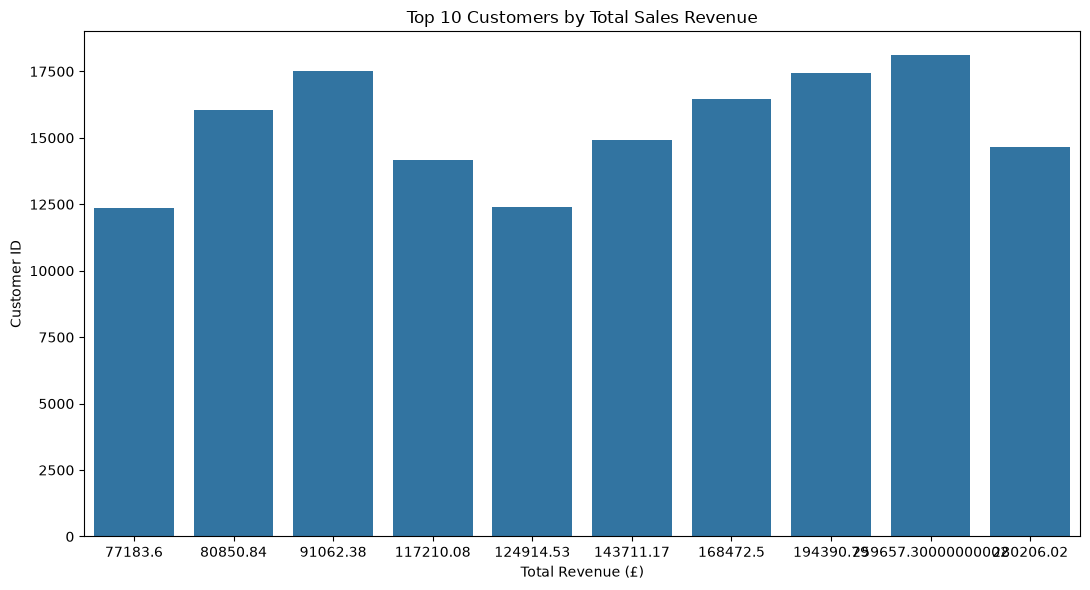

In [26]:
# Plot the ten customers with the highest total sales revenue
plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_customers,
    x="TotalRevenue",
    y="CustomerID"
)

plt.title("Top 10 Customers by Total Sales Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [27]:
# Measure repeat customers and their share among identified customers
customer_summary["IsRepeatCustomer"] = (
    customer_summary["TotalOrders"] >= 2
)

identified_customer_count = len(customer_summary)

repeat_customer_count = customer_summary["IsRepeatCustomer"].sum()

repeat_customer_percentage = (
    repeat_customer_count / identified_customer_count * 100
    if identified_customer_count > 0
    else 0
)

print(f"Identified customers: {identified_customer_count:,}")
print(f"Repeat customers: {repeat_customer_count:,}")
print(f"Repeat customer rate: {repeat_customer_percentage:.2f}%")

Identified customers: 4,338
Repeat customers: 2,845
Repeat customer rate: 65.58%


In [28]:
import numpy as np

# Compare revenue and customer counts for one-time and repeat customers
customer_summary["CustomerType"] = np.where(
    customer_summary["IsRepeatCustomer"],
    "Repeat Customer",
    "One-time Customer"
)

customer_type_summary = (
    customer_summary
    .groupby("CustomerType", as_index=False)
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        TotalRevenue=("TotalRevenue", "sum"),
        AverageCustomerRevenue=("TotalRevenue", "mean"),
        AverageOrders=("TotalOrders", "mean")
    )
)

customer_type_summary

,CustomerType,CustomerCount,TotalRevenue,AverageCustomerRevenue,AverageOrders
0,One-time Customer,1493,613989.561,411.245520,1.000000
1,Repeat Customer,2845,8273219.333,2907.985706,5.989104


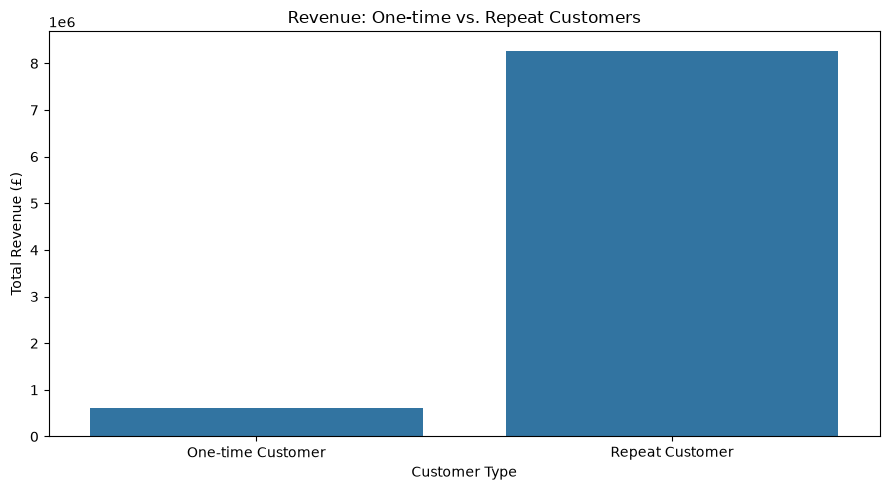

In [29]:
# Compare total revenue generated by one-time and repeat customers
plt.figure(figsize=(9, 5))

sns.barplot(
    data=customer_type_summary,
    x="CustomerType",
    y="TotalRevenue"
)

plt.title("Revenue: One-time vs. Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Total Revenue (£)")
plt.tight_layout()
plt.show()

In [30]:
# Calculate average order value for invoices with identifiable customers
total_identified_sales = invoice_sales["OrderValue"].sum()
identified_invoice_count = invoice_sales["InvoiceNo"].nunique()

average_order_value = (
    total_identified_sales / identified_invoice_count
    if identified_invoice_count > 0
    else 0
)

print(f"Identified-customer sales revenue: £{total_identified_sales:,.2f}")
print(f"Qualifying invoices: {identified_invoice_count:,}")
print(f"Average order value: £{average_order_value:,.2f}")

Identified-customer sales revenue: £8,887,208.89
Qualifying invoices: 18,532
Average order value: £479.56


In [31]:
from pathlib import Path

# Export customer-level and customer-group summaries
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

customer_summary.to_csv(
    reports_dir / "customer_summary.csv",
    index=False
)

customer_type_summary.to_csv(
    reports_dir / "customer_type_summary.csv",
    index=False
)

invoice_sales.to_csv(
    reports_dir / "identified_invoice_sales.csv",
    index=False
)

print("Customer summary saved.")
print("Customer type summary saved.")
print("Identified invoice sales saved.")

Customer summary saved.
Customer type summary saved.
Identified invoice sales saved.


# 8. RFM Analysis and Customer Segmentation

RFM analysis is a data-driven customer segmentation technique that evaluates customer value based on three key behavioral metrics:

- **Recency (R):** How recently a customer made a purchase. Customers who bought recently are more likely to respond to new offers.
- **Frequency (F):** How often a customer makes a purchase. High frequency indicates strong brand loyalty and engagement.
- **Monetary Value (M):** How much money a customer spends. High spending highlights top-tier revenue contributors.

By scoring customers on these three dimensions, RFM analysis helps businesses identify their most valuable loyalists, spot at-risk customers who may be churning, and tailor marketing efforts effectively.

The analysis uses positive sales transactions with identifiable customer IDs. The reference date is set to one day after the latest transaction date available in the dataset.

In [32]:
# Calculate recency, frequency, and monetary value for each customer
reference_date = retail["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    invoice_sales
    .groupby("CustomerID", as_index=False)
    .agg(
        LastPurchaseDate=("OrderDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("OrderValue", "sum")
    )
)

rfm["Recency"] = (reference_date - rfm["LastPurchaseDate"].dt.normalize()).dt.days

rfm = rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary", "LastPurchaseDate"]
]

rfm.head()

,CustomerID,Recency,Frequency,Monetary,LastPurchaseDate
0,12346.0,326,1,77183.60,2011-01-18 10:01:00
1,12347.0,3,7,4310.00,2011-12-07 15:52:00
2,12348.0,76,4,1797.24,2011-09-25 13:13:00
3,12349.0,19,1,1757.55,2011-11-21 09:51:00
4,12350.0,311,1,334.40,2011-02-02 16:01:00


In [33]:
# Assign 1-to-5 RFM scores using customer quintiles
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first", ascending=True),
    q=5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    q=5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

rfm.head(10)

,CustomerID,Recency,Frequency,Monetary,LastPurchaseDate,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,2011-01-18 10:01:00,1,1,5,115
1,12347.0,3,7,4310.00,2011-12-07 15:52:00,5,5,5,555
2,12348.0,76,4,1797.24,2011-09-25 13:13:00,2,4,4,244
3,12349.0,19,1,1757.55,2011-11-21 09:51:00,4,1,4,414
4,12350.0,311,1,334.40,2011-02-02 16:01:00,1,1,2,112
5,12352.0,37,8,2506.04,2011-11-03 14:37:00,3,5,5,355
6,12353.0,205,1,89.00,2011-05-19 17:47:00,1,1,1,111
7,12354.0,233,1,1079.40,2011-04-21 13:11:00,1,1,4,114
8,12355.0,215,1,459.40,2011-05-09 13:49:00,1,1,2,112
9,12356.0,23,3,2811.43,2011-11-17 08:40:00,4,3,5,435


In [34]:
# Classify customers into actionable RFM segments
def assign_customer_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:
        return "Champions"
    elif r >= 3 and f >= 4:
        return "Loyal Customers"
    elif r >= 4 and f >= 2 and m >= 3:
        return "Potential Loyalists"
    elif r >= 4 and f == 1:
        return "Recent Customers"
    elif r <= 2 and f >= 4 and m >= 3:
        return "At Risk"
    elif r <= 2 and f <= 2 and m <= 2:
        return "Lost / Low Engagement"
    elif r <= 2:
        return "Needs Attention"
    else:
        return "Regular Customers"

rfm["CustomerSegment"] = rfm.apply(assign_customer_segment, axis=1)

rfm[["CustomerID", "R_Score", "F_Score", "M_Score", "RFM_Score", "CustomerSegment"]].head(10)

,CustomerID,R_Score,F_Score,M_Score,RFM_Score,CustomerSegment
0,12346.0,1,1,5,115,Needs Attention
1,12347.0,5,5,5,555,Champions
2,12348.0,2,4,4,244,At Risk
3,12349.0,4,1,4,414,Recent Customers
4,12350.0,1,1,2,112,Lost / Low Engagement
5,12352.0,3,5,5,355,Loyal Customers
6,12353.0,1,1,1,111,Lost / Low Engagement
7,12354.0,1,1,4,114,Needs Attention
8,12355.0,1,1,2,112,Lost / Low Engagement
9,12356.0,4,3,5,435,Potential Loyalists


In [35]:
# Summarize customer counts, spending, and RFM metrics by segment
segment_summary = (
    rfm
    .groupby("CustomerSegment", as_index=False)
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        TotalRevenue=("Monetary", "sum"),
        AverageCustomerRevenue=("Monetary", "mean"),
        AverageRecencyDays=("Recency", "mean"),
        AverageFrequency=("Frequency", "mean")
    )
    .sort_values("TotalRevenue", ascending=False)
)

segment_summary["CustomerSharePct"] = (
    segment_summary["CustomerCount"] / len(rfm) * 100
)

segment_summary["RevenueSharePct"] = (
    segment_summary["TotalRevenue"] / rfm["Monetary"].sum() * 100
)

segment_summary.round(2)

,CustomerSegment,CustomerCount,TotalRevenue,AverageCustomerRevenue,AverageRecencyDays,AverageFrequency,CustomerSharePct,RevenueSharePct
1,Champions,941,5741913.58,6101.93,12.98,11.21,21.69,64.61
3,Loyal Customers,504,918045.60,1821.52,37.37,5.12,11.62,10.33
4,Needs Attention,659,715420.00,1085.61,170.38,2.00,15.19,8.05
0,At Risk,252,446789.82,1772.98,130.88,5.05,5.81,5.03
5,Potential Loyalists,252,435999.24,1730.16,17.03,2.32,5.81,4.91
7,Regular Customers,770,397001.71,515.59,42.37,1.60,17.75,4.47
2,Lost / Low Engagement,824,188415.28,228.66,228.09,1.04,18.99,2.12
6,Recent Customers,136,43623.66,320.76,18.54,1.00,3.14,0.49


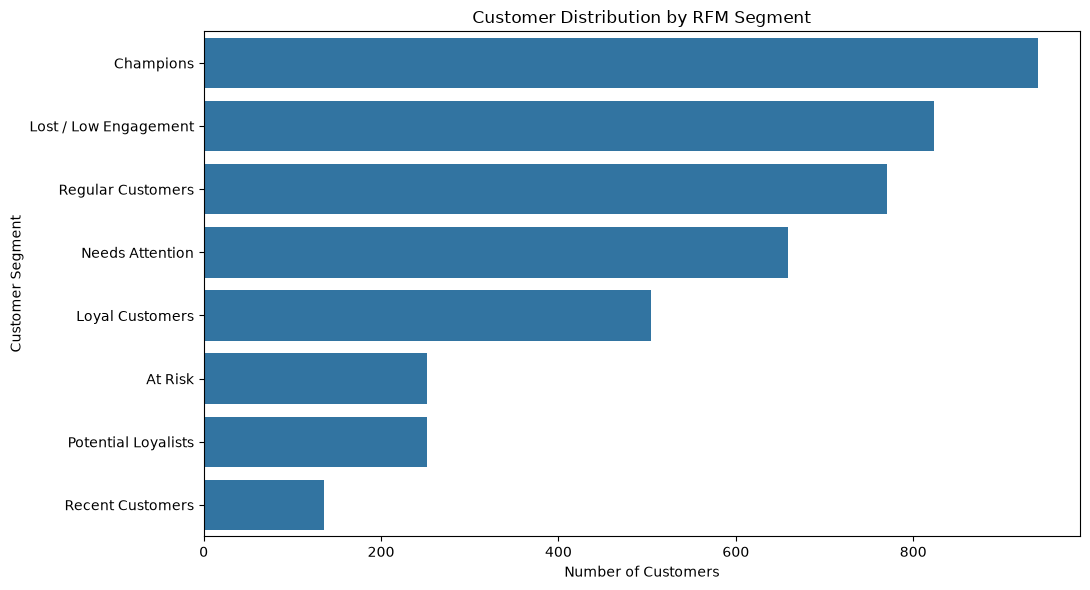

In [36]:
# Visualize the number of customers in each RFM segment
segment_by_customers = segment_summary.sort_values(
    "CustomerCount",
    ascending=False
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=segment_by_customers,
    x="CustomerCount",
    y="CustomerSegment"
)
plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

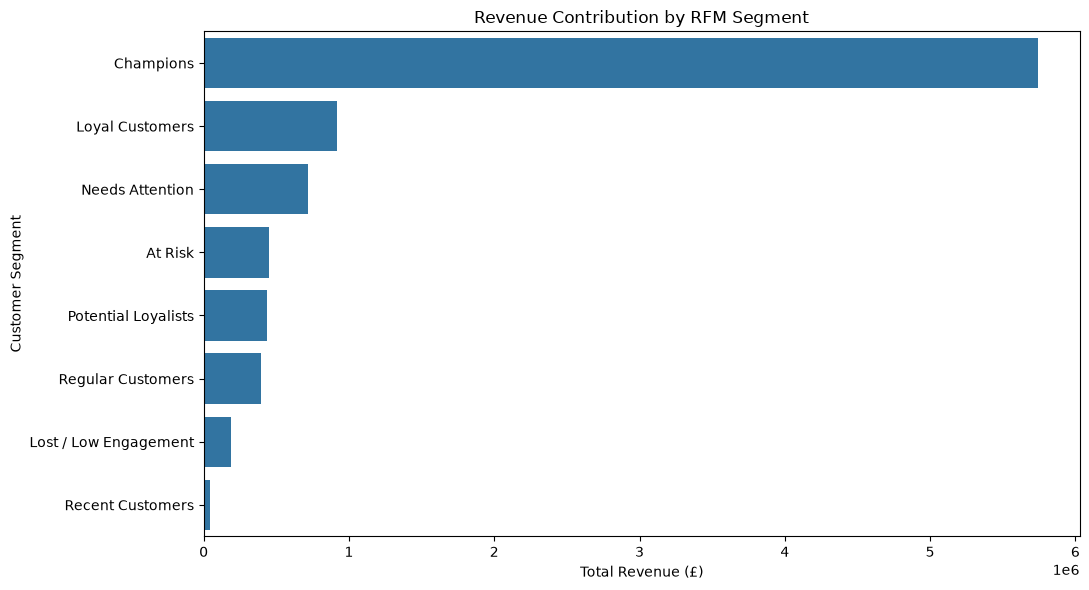

In [37]:
# Visualize total revenue generated by each RFM segment
segment_by_revenue = segment_summary.sort_values(
    "TotalRevenue",
    ascending=False
)

plt.figure(figsize=(11, 6))
sns.barplot(
    data=segment_by_revenue,
    x="TotalRevenue",
    y="CustomerSegment"
)
plt.title("Revenue Contribution by RFM Segment")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

In [38]:
# Create a shortlist of customers who may need re-engagement
retention_segments = ["At Risk", "Needs Attention"]

retention_list = (
    rfm.loc[rfm["CustomerSegment"].isin(retention_segments)]
    .sort_values(
        ["Monetary", "Recency"],
        ascending=[False, False]
    )
)

retention_list.head(20)

,CustomerID,Recency,Frequency,Monetary,LastPurchaseDate,R_Score,F_Score,M_Score,RFM_Score,CustomerSegment
0,12346.0,326,1,77183.60,2011-01-18 10:01:00,1,1,5,115,Needs Attention
2502,15749.0,236,3,44534.30,2011-04-18 13:20:00,1,3,5,135,Needs Attention
2011,15098.0,183,3,39916.50,2011-06-10 15:33:00,1,3,5,135,Needs Attention
50,12409.0,79,3,11072.67,2011-09-22 10:38:00,2,3,5,235,Needs Attention
2814,16180.0,101,8,10254.18,2011-08-31 16:28:00,2,5,5,255,At Risk
196,12590.0,212,2,9864.26,2011-05-12 14:52:00,1,2,5,125,Needs Attention
566,13093.0,276,8,7832.47,2011-03-09 12:14:00,1,5,5,155,At Risk
73,12435.0,80,2,7829.89,2011-09-21 09:06:00,2,2,5,225,Needs Attention
485,12980.0,158,9,7374.90,2011-07-05 09:34:00,2,5,5,255,At Risk
3222,16745.0,87,17,7180.70,2011-09-14 11:58:00,2,5,5,255,At Risk


In [39]:
# Export RFM scores, segment summaries, and retention candidates
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

rfm.to_csv(reports_dir / "customer_rfm_segments.csv", index=False)
segment_summary.to_csv(reports_dir / "rfm_segment_summary.csv", index=False)
retention_list.to_csv(reports_dir / "customer_retention_candidates.csv", index=False)

print("RFM customer segments saved.")
print("RFM segment summary saved.")
print("Retention shortlist saved.")

RFM customer segments saved.
RFM segment summary saved.
Retention shortlist saved.


# 9. Customer Retention and Cohort Analysis

Customer retention analysis measures whether customers return after their initial purchase. Cohort analysis groups customers by the month of their first qualifying purchase and tracks their subsequent purchasing activity over time.

This analysis uses positive sales invoices belonging to identifiable customers. Retention is measured by purchase activity in a month, not by whether a customer is continuously active or permanently retained.

In [40]:
# Prepare invoice-level data for customer retention analysis
retention_data = invoice_sales.copy()

retention_data["OrderDate"] = pd.to_datetime(retention_data["OrderDate"])
retention_data["InvoiceMonth"] = (
    retention_data["OrderDate"].dt.to_period("M")
)

retention_data.head()

,CustomerID,InvoiceNo,OrderValue,OrderDate,UnitsPurchased,InvoiceMonth
0,12346.0,541431,77183.60,2011-01-18 10:01:00,74215,2011-01
1,12347.0,537626,711.79,2010-12-07 14:57:00,319,2010-12
2,12347.0,542237,475.39,2011-01-26 14:30:00,315,2011-01
3,12347.0,549222,636.25,2011-04-07 10:43:00,483,2011-04
4,12347.0,556201,382.52,2011-06-09 13:01:00,196,2011-06


In [41]:
import numpy as np

# Calculate the distribution of customers by number of orders
orders_per_customer = (
    retention_data
    .groupby("CustomerID")
    .agg(TotalOrders=("InvoiceNo", "nunique"))
    .reset_index()
)

orders_per_customer["PurchaseCategory"] = np.where(
    orders_per_customer["TotalOrders"] >= 2,
    "Repeat Purchaser",
    "One-time Purchaser"
)

purchase_category_summary = (
    orders_per_customer
    .groupby("PurchaseCategory", as_index=False)
    .agg(CustomerCount=("CustomerID", "nunique"))
)

purchase_category_summary["CustomerSharePct"] = (
    purchase_category_summary["CustomerCount"]
    / purchase_category_summary["CustomerCount"].sum()
    * 100
)

purchase_category_summary.round(2)

,PurchaseCategory,CustomerCount,CustomerSharePct
0,One-time Purchaser,1493,34.42
1,Repeat Purchaser,2845,65.58


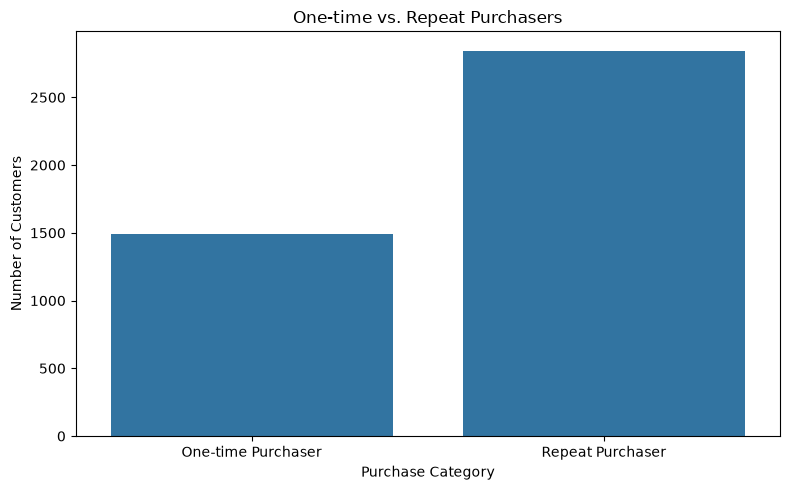

In [42]:
# Plot the distribution of one-time and repeat purchasers
plt.figure(figsize=(8, 5))
sns.barplot(
    data=purchase_category_summary,
    x="PurchaseCategory",
    y="CustomerCount"
)
plt.title("One-time vs. Repeat Purchasers")
plt.xlabel("Purchase Category")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [43]:
# Assign each customer to their first purchase month
customer_cohorts = (
    retention_data
    .groupby("CustomerID", as_index=False)
    .agg(FirstPurchaseMonth=("InvoiceMonth", "min"))
)

retention_data = retention_data.merge(
    customer_cohorts,
    on="CustomerID",
    how="left"
)

retention_data.head()

,CustomerID,InvoiceNo,OrderValue,OrderDate,UnitsPurchased,InvoiceMonth,FirstPurchaseMonth
0,12346.0,541431,77183.60,2011-01-18 10:01:00,74215,2011-01,2011-01
1,12347.0,537626,711.79,2010-12-07 14:57:00,319,2010-12,2010-12
2,12347.0,542237,475.39,2011-01-26 14:30:00,315,2011-01,2010-12
3,12347.0,549222,636.25,2011-04-07 10:43:00,483,2011-04,2010-12
4,12347.0,556201,382.52,2011-06-09 13:01:00,196,2011-06,2010-12


In [44]:
# Calculate the number of months since each customer's first purchase month
retention_data["CohortMonthIndex"] = (
    (retention_data["InvoiceMonth"].dt.year
     - retention_data["FirstPurchaseMonth"].dt.year) * 12
    + (retention_data["InvoiceMonth"].dt.month
       - retention_data["FirstPurchaseMonth"].dt.month)
)

retention_data[
    ["CustomerID", "InvoiceMonth", "FirstPurchaseMonth", "CohortMonthIndex"]
].head(10)

,CustomerID,InvoiceMonth,FirstPurchaseMonth,CohortMonthIndex
0,12346.0,2011-01,2011-01,0
1,12347.0,2010-12,2010-12,0
2,12347.0,2011-01,2010-12,1
3,12347.0,2011-04,2010-12,4
4,12347.0,2011-06,2010-12,6
5,12347.0,2011-08,2010-12,8
6,12347.0,2011-10,2010-12,10
7,12347.0,2011-12,2010-12,12
8,12348.0,2010-12,2010-12,0
9,12348.0,2011-01,2010-12,1


In [45]:
# Count unique active customers for each cohort and cohort month
cohort_data = (
    retention_data
    .groupby(
        ["FirstPurchaseMonth", "CohortMonthIndex"]
    )["CustomerID"]
    .nunique()
    .reset_index(name="ActiveCustomers")
)

cohort_counts = cohort_data.pivot(
    index="FirstPurchaseMonth",
    columns="CohortMonthIndex",
    values="ActiveCustomers"
)

cohort_counts

CohortMonthIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
FirstPurchaseMonth,,,,,,,,,,,,,
2010-12,885.0,324.0,286.0,340.0,321.0,352.0,321.0,309.0,313.0,350.0,331.0,445.0,235.0
2011-01,417.0,92.0,111.0,96.0,134.0,120.0,103.0,101.0,125.0,136.0,152.0,49.0,NaN
2011-02,380.0,71.0,71.0,108.0,103.0,94.0,96.0,106.0,94.0,116.0,26.0,NaN,NaN
2011-03,452.0,68.0,114.0,90.0,101.0,76.0,121.0,104.0,126.0,39.0,NaN,NaN,NaN
2011-04,300.0,64.0,61.0,63.0,59.0,68.0,65.0,78.0,22.0,NaN,NaN,NaN,NaN
2011-05,284.0,54.0,49.0,49.0,59.0,66.0,75.0,27.0,NaN,NaN,NaN,NaN,NaN
2011-06,242.0,42.0,38.0,64.0,56.0,81.0,23.0,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,188.0,34.0,39.0,42.0,51.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,169.0,35.0,42.0,41.0,21.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [46]:
# Calculate monthly retention percentages relative to each cohort's initial size
cohort_sizes = cohort_counts.iloc[:, 0]

cohort_retention = cohort_counts.div(cohort_sizes, axis=0) * 100

cohort_retention = cohort_retention.round(2)

cohort_retention

CohortMonthIndex,0,1,2,3,4,5,6,7,8,9,10,11,12
FirstPurchaseMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


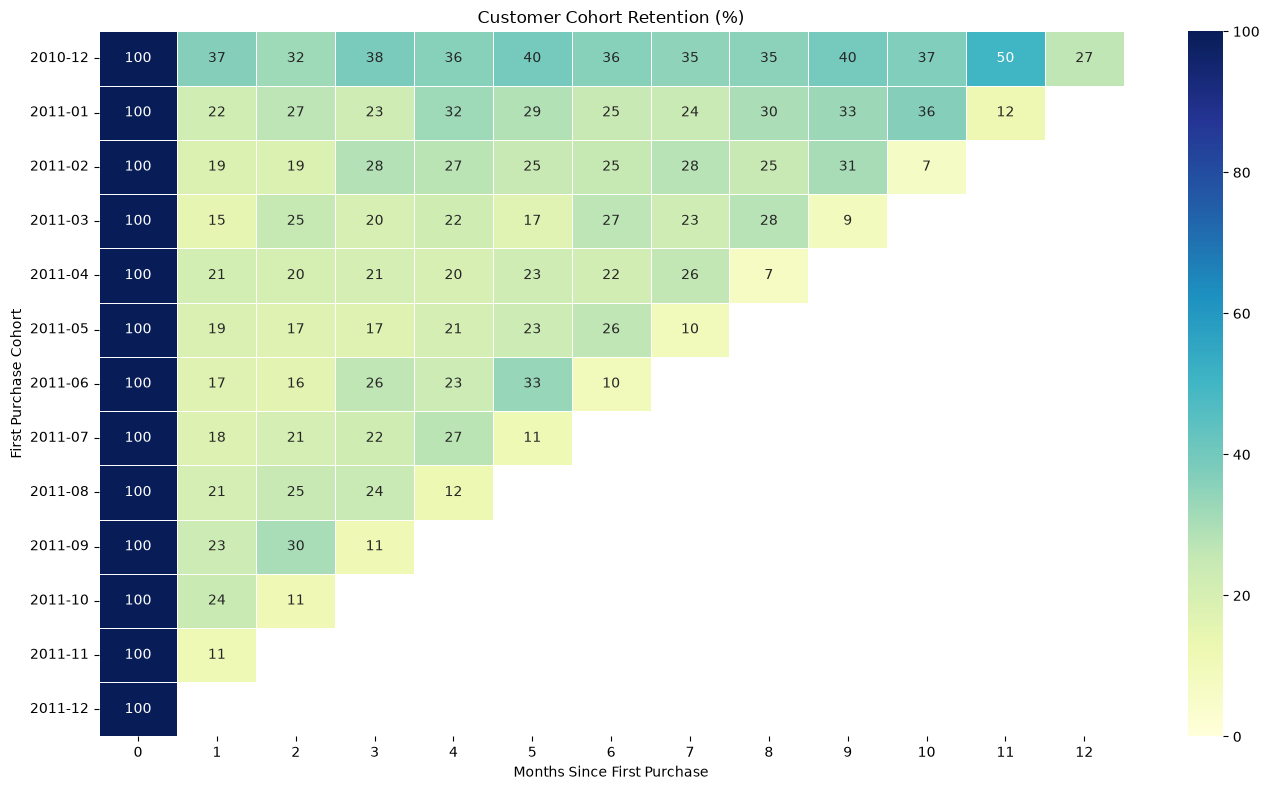

In [47]:
# Visualize monthly cohort retention with a heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5
)

plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Cohort")
plt.tight_layout()
plt.show()

In [48]:
# Summarize month-one retention for cohorts with an observed follow-up month
if 1 in cohort_retention.columns:
    month_one_retention = cohort_retention[[1]].rename(
        columns={1: "Month1RetentionPct"}
    ).dropna()

    month_one_retention = month_one_retention.sort_index()

    display(month_one_retention)
else:
    print("Month-one retention is unavailable for the current cohort table.")

CohortMonthIndex,Month1RetentionPct
FirstPurchaseMonth,
2010-12,36.61
2011-01,22.06
2011-02,18.68
2011-03,15.04
2011-04,21.33
2011-05,19.01
2011-06,17.36
2011-07,18.09
2011-08,20.71


In [49]:
from pathlib import Path

# Export customer retention and cohort analysis results
reports_dir = project_root / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

purchase_category_summary.to_csv(
    reports_dir / "purchase_category_summary.csv",
    index=False
)

cohort_counts.to_csv(
    reports_dir / "cohort_customer_counts.csv"
)

cohort_retention.to_csv(
    reports_dir / "cohort_retention_percentages.csv"
)

if 'month_one_retention' in locals():
    month_one_retention.to_csv(
        reports_dir / "month_one_retention.csv"
    )

print("Purchase category summary saved.")
print("Cohort customer counts saved.")
print("Cohort retention percentages saved.")
print("Month-one retention summary saved.")

Purchase category summary saved.
Cohort customer counts saved.
Cohort retention percentages saved.
Month-one retention summary saved.
